# Chapter 5. Evaluation

## 5.1 Noise Estimation on the Test Set

The final edge-aware Laplacian estimator is evaluated on 100 unseen test images. The flat-region fraction is fixed at 4%.


## 1. Experiment Setup

Noise levels from 2% to 15% are tested. Each image-noise case uses a reproducible noise realisation.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from joblib import Parallel, delayed
from scipy.signal import convolve2d

# Find the project directory
project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_dir) not in sys.path:
    sys.path.append(str(project_dir))

from src.noise import add_gaussian_noise
from src.noise_level_estimators import edge_aware_laplacian_noise_estimate
from src.utils import load_grayscale_image


In [2]:
# Final test settings
noise_levels = list(range(2, 16))
flat_fraction = 0.04
seed = 42
num_test_images = 100
n_jobs = 16

test_dir = project_dir / "data" / "test"
result_dir = project_dir / "results" / "Chapter5_EvaluateNoiseEstimation"
result_dir.mkdir(parents=True, exist_ok=True)

print("Test directory:", test_dir)
print("Noise levels (%):", noise_levels)
print("Flat-region fraction:", f"{flat_fraction:.0%}")
print("Base seed:", seed)
print("Parallel jobs:", n_jobs)


Test directory: D:\MScProject\data\test
Noise levels (%): [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
Flat-region fraction: 4%
Base seed: 42
Parallel jobs: 16


In [3]:
# Load the 100 unseen test images
image_files = []
for pattern in ["*.png", "*.jpg", "*.jpeg", "*.bmp", "*.tif", "*.tiff"]:
    image_files.extend(test_dir.rglob(pattern))

image_files = sorted(set(image_files))
if len(image_files) != num_test_images:
    raise FileNotFoundError(
        f"Expected exactly {num_test_images} test images, but found {len(image_files)} in {test_dir}"
    )

test_images = [(image_file.stem, load_grayscale_image(image_file)) for image_file in image_files]

# Check the input images
for image_name, clean_image in test_images:
    if clean_image.ndim != 2:
        raise ValueError(f"{image_name} is not a grayscale image")
    if clean_image.min() < 0 or clean_image.max() > 1:
        raise ValueError(f"{image_name} is not normalised to [0, 1]")

print("Number of test images:", len(test_images))
print("First test image:", test_images[0][0])
print("Last test image:", test_images[-1][0])


Number of test images: 100
First test image: 001
Last test image: 100


## 2. Noise-Estimation Evaluation

The estimator is evaluated at each noise level. MRE, MAE, RMSE, and bias are calculated from the test cases.


In [4]:
# Derive one reproducible seed for each image-noise case
def make_case_seed(image_index, noise_percent):
    noise_index = noise_levels.index(noise_percent)
    return seed + noise_index * num_test_images + image_index


def evaluate_test_case(image_index, image_name, clean_image, noise_percent):
    noisy_image = add_gaussian_noise(
        clean_image, sigma=noise_percent / 100,
        seed=make_case_seed(image_index, noise_percent)
    ).astype(np.float32)

    estimated_percent = 100 * float(
        edge_aware_laplacian_noise_estimate(noisy_image, flat_fraction=flat_fraction)
    )

    signed_error = estimated_percent - noise_percent
    absolute_error = abs(signed_error)

    return {
        "image": image_name,
        "image_index": image_index,
        "true_noise_percent": noise_percent,
        "estimated_noise_percent": estimated_percent,
        "signed_error_pp": signed_error,
        "absolute_error_pp": absolute_error,
        "squared_error_pp2": signed_error ** 2,
        "relative_error_percent": absolute_error / noise_percent * 100
    }


test_rows = Parallel(n_jobs=n_jobs, prefer="threads", verbose=5)(
    delayed(evaluate_test_case)(image_index, image_name, clean_image, noise_percent)
    for noise_percent in noise_levels
    for image_index, (image_name, clean_image) in enumerate(test_images)
)

test_results = (
    pd.DataFrame(test_rows)
    .sort_values(["true_noise_percent", "image_index"])
    .reset_index(drop=True)
)

expected_cases = num_test_images * len(noise_levels)
if len(test_results) != expected_cases:
    raise RuntimeError(f"Expected {expected_cases} test cases, but obtained {len(test_results)}")

if not np.isfinite(test_results.select_dtypes(include="number")).all().all():
    raise ValueError("The test results contain a non-finite value")

print("Completed test cases:", len(test_results))
display(test_results.head())


[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  40 tasks      | elapsed:    0.5s
[Parallel(n_jobs=16)]: Done 130 tasks      | elapsed:    1.5s
[Parallel(n_jobs=16)]: Done 256 tasks      | elapsed:    2.8s
[Parallel(n_jobs=16)]: Done 418 tasks      | elapsed:    4.6s
[Parallel(n_jobs=16)]: Done 616 tasks      | elapsed:    6.7s
[Parallel(n_jobs=16)]: Done 850 tasks      | elapsed:    9.2s
[Parallel(n_jobs=16)]: Done 1120 tasks      | elapsed:   12.0s


Completed test cases: 1400


[Parallel(n_jobs=16)]: Done 1400 out of 1400 | elapsed:   14.8s finished


,image,image_index,true_noise_percent,estimated_noise_percent,signed_error_pp,absolute_error_pp,squared_error_pp2,relative_error_percent
0,001,0,2,2.930928,0.930928,0.930928,0.866627,46.546403
1,002,1,2,2.051222,0.051222,0.051222,0.002624,2.561113
2,003,2,2,2.077381,0.077381,0.077381,0.005988,3.869051
3,004,3,2,2.058982,0.058982,0.058982,0.003479,2.949101
4,005,4,2,2.129085,0.129085,0.129085,0.016663,6.454262


In [5]:
# Summarise performance at each noise level
level_summary = (
    test_results.groupby("true_noise_percent", as_index=False)
    .agg(
        mean_estimate_percent=("estimated_noise_percent", "mean"),
        estimate_std_percent=("estimated_noise_percent", "std"),
        mre_percent=("relative_error_percent", "mean"),
        mae_pp=("absolute_error_pp", "mean"),
        rmse_pp=("squared_error_pp2", lambda values: np.sqrt(values.mean())),
        bias_pp=("signed_error_pp", "mean")
    )
)

# Calculate overall measures across all test cases
overall_summary = pd.DataFrame([{
    "Estimator": "Edge-aware Laplacian (4%)",
    "Test cases": len(test_results),
    "Overall MRE (%)": test_results["relative_error_percent"].mean(),
    "MAE (pp)": test_results["absolute_error_pp"].mean(),
    "RMSE (pp)": np.sqrt(test_results["squared_error_pp2"].mean()),
    "Bias (pp)": test_results["signed_error_pp"].mean()
}])


## 3. Estimated and True Noise Levels

The mean estimate is compared with the true noise level.


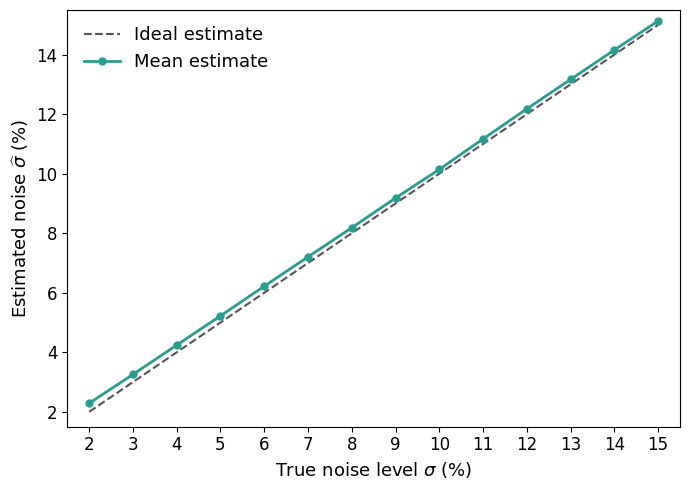

In [6]:
# Compare mean estimated and true noise levels
fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(noise_levels, noise_levels, color="#555555", linestyle="--",
        linewidth=1.5, label="Ideal estimate")
ax.plot(level_summary["true_noise_percent"], level_summary["mean_estimate_percent"],
        color="#2a9d8f", marker="o", markersize=5, linewidth=2, label="Mean estimate")

ax.set_xlabel(r"True noise level $\sigma$ (%)", fontsize=13)
ax.set_ylabel(r"Estimated noise $\widehat{\sigma}$ (%)", fontsize=13)
ax.set_xticks(noise_levels)
ax.set_xlim(1.5, 15.5)
ax.set_ylim(1.5, 15.5)
ax.tick_params(axis="both", labelsize=12)
ax.legend(frameon=False, fontsize=13)

fig.tight_layout()
fig.savefig(result_dir / "test_estimated_vs_true_noise.png", dpi=300, bbox_inches="tight")
plt.show()


## 4. MRE at Each Noise Level

Mean estimated noise and MRE are reported for each noise level.


In [7]:
level_mre_table = (
    level_summary[["true_noise_percent", "mean_estimate_percent", "mre_percent"]]
    .rename(columns={
        "true_noise_percent": "True noise level (%)",
        "mean_estimate_percent": "Mean estimate (%)",
        "mre_percent": "MRE (%)"
    })
    .round(3)
)

display(level_mre_table)


,True noise level (%),Mean estimate (%),MRE (%)
0,2,2.287,14.385
1,3,3.257,8.580
2,4,4.241,6.083
3,5,5.223,4.495
4,6,6.220,3.781
5,7,7.205,3.063
6,8,8.186,2.483
7,9,9.183,2.210
8,10,10.144,1.809
9,11,11.168,1.739


## 5. Overall Summary

The overall measures are calculated across all test cases.


In [8]:
display(overall_summary.round(3))


,Estimator,Test cases,Overall MRE (%),MAE (pp),RMSE (pp),Bias (pp)
0,Edge-aware Laplacian (4%),1400,3.902,0.216,0.334,0.196


## 6. Example Test Cases

The examples compare one image at three noise levels and three images at the same noise level.


In [9]:
# Kernels used by the diagnostic figure
laplacian_kernel = np.array([
    [1, -2, 1],
    [-2, 4, -2],
    [1, -2, 1]
], dtype=np.float64)

gradient_x_kernel = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float64)

gradient_y_kernel = gradient_x_kernel.T


def calculate_edge_aware_details(noisy_image):
    gradient_x = convolve2d(noisy_image, gradient_x_kernel, mode="valid")
    gradient_y = convolve2d(noisy_image, gradient_y_kernel, mode="valid")
    gradient_magnitude = np.hypot(gradient_x, gradient_y)

    # Retain the lowest-gradient positions
    threshold = np.quantile(gradient_magnitude, flat_fraction)
    flat_mask = gradient_magnitude <= threshold

    laplacian_response = convolve2d(noisy_image, laplacian_kernel, mode="valid")
    absolute_response = np.abs(laplacian_response)
    cropped_noisy_image = noisy_image[1:-1, 1:-1]

    return cropped_noisy_image, flat_mask, absolute_response


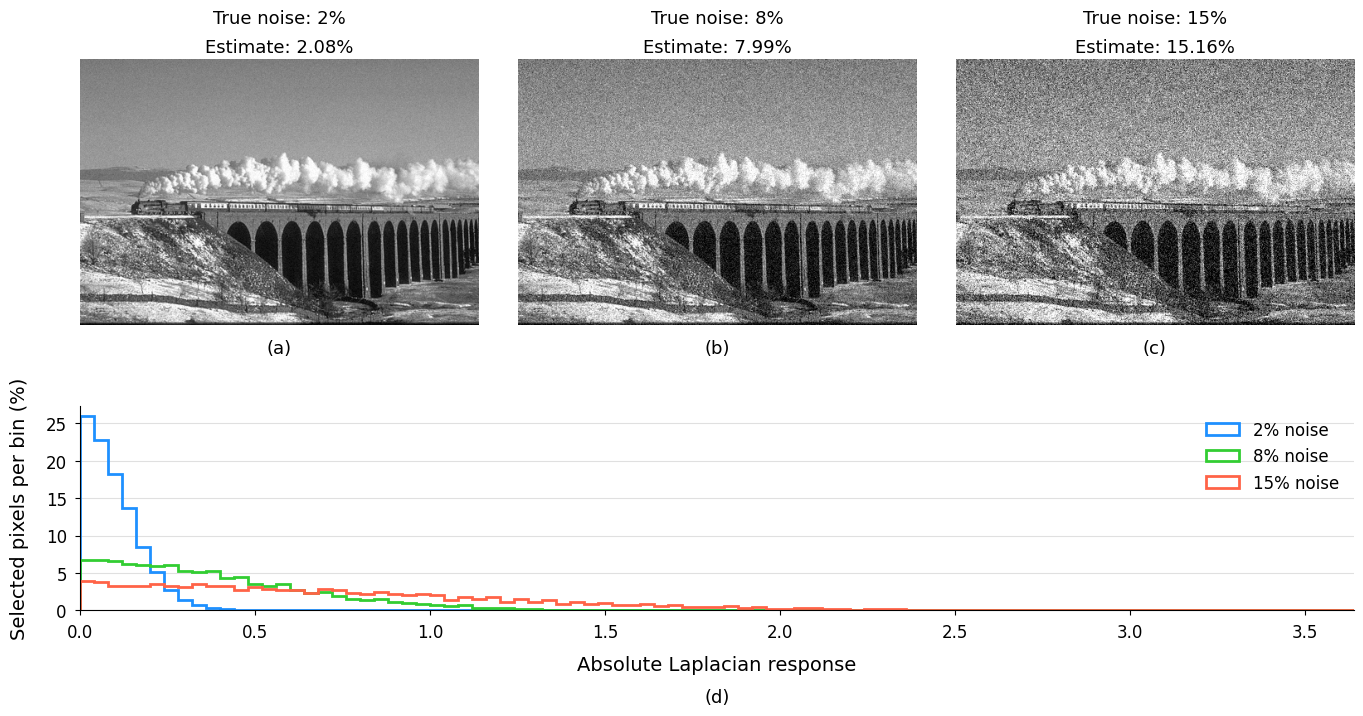

Example image: 034


In [10]:
# Example settings
same_image_index = 33
same_image_noise_levels = [2, 8, 15]

if same_image_index < 0 or same_image_index >= len(test_images):
    raise IndexError("The example image index is outside the test set")


def create_example_record(image_index, noise_level):
    image_name, clean_image = test_images[image_index]
    noisy_image = add_gaussian_noise(
        clean_image, sigma=noise_level / 100,
        seed=make_case_seed(image_index, noise_level)
    ).astype(np.float32)

    estimate = 100 * float(
        edge_aware_laplacian_noise_estimate(noisy_image, flat_fraction=flat_fraction)
    )

    cropped_image, flat_mask, response = calculate_edge_aware_details(noisy_image)

    return {
        "image_name": image_name,
        "noise_level": noise_level,
        "noisy_image": noisy_image,
        "cropped_image": cropped_image,
        "estimate": estimate,
        "flat_mask": flat_mask,
        "response": response
    }


def plot_example_records(records, output_name):
    selected_responses = [record["response"][record["flat_mask"]] for record in records]

    all_responses = np.concatenate(selected_responses)
    bin_width = 0.04
    response_xmax = np.ceil(all_responses.max() / bin_width) * bin_width
    response_bins = np.arange(0, response_xmax + bin_width, bin_width)

    colours = ["#1E90FF", "#32CD32", "#FF6347"]
    fig = plt.figure(figsize=(14, 6.8))
    grid = fig.add_gridspec(2, 3, height_ratios=[1, 0.75], wspace=0.10, hspace=0.34)
    top_axes = [fig.add_subplot(grid[0, column]) for column in range(3)]
    histogram_ax = fig.add_subplot(grid[1, :])

    for column, (record, response_values) in enumerate(zip(records, selected_responses)):
        top_ax = top_axes[column]
        top_ax.imshow(record["noisy_image"], cmap="gray", vmin=0, vmax=1)
        top_ax.set_title(
            f"True noise: {record['noise_level']}%\nEstimate: {record['estimate']:.2f}%",
            fontsize=13, pad=5, linespacing=1.8
        )
        top_ax.axis("off")
        top_ax.set_anchor("S")
        top_ax.text(
            0.5, -0.055, f"({chr(97 + column)})",
            transform=top_ax.transAxes, ha="center", va="top", fontsize=13
        )

        weights = np.full(response_values.shape, 100 / response_values.size)
        histogram_ax.hist(
            response_values, bins=response_bins, weights=weights, histtype="step",
            linewidth=2, color=colours[column], label=f"{record['noise_level']}% noise"
        )

    histogram_ax.set_xlim(0, response_xmax)
    histogram_ax.set_xlabel("Absolute Laplacian response", fontsize=14, labelpad=10)
    histogram_ax.set_ylabel("Selected pixels per bin (%)", fontsize=14, labelpad=12)
    histogram_ax.tick_params(axis="both", labelsize=12, pad=6)
    histogram_ax.set_axisbelow(True)
    histogram_ax.grid(axis="y", color="#d9d9d9", linewidth=0.8, alpha=0.8)
    histogram_ax.legend(frameon=False, fontsize=12)
    histogram_ax.spines["top"].set_visible(False)
    histogram_ax.spines["right"].set_visible(False)
    histogram_ax.text(
        0.5, -0.38, "(d)", transform=histogram_ax.transAxes,
        ha="center", va="top", fontsize=13
    )

    fig.subplots_adjust(left=0.07, right=0.98, top=0.97, bottom=0.15)
    fig.savefig(result_dir / output_name, dpi=300, bbox_inches="tight")
    plt.show()


# One image at three noise levels
same_image_records = [
    create_example_record(same_image_index, noise_level)
    for noise_level in same_image_noise_levels
]

plot_example_records(same_image_records, "test_one_image_three_noise_levels.png")

print("Example image:", test_images[same_image_index][0])
